<div align="center">

# Diagnóstico, Baselines e ARIMA/SARIMA
<hr>

### Séries Temporais, FGV EMAp - 2026/2 ###

Bryan Santos Monteiro<br>
João Vitor Tomaz Alves Ferreira<br>
Nicholas Costa<br>
Roger Vinícius Pereira Augusto<br>
Sofia Azeredo de Moura Monteiro<br>
Vinício Vasconcelos Muniz Deusdará

</div>

In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from src.dados import carregar_split, SERIES
from src.diagnostico import figura_diagnostico, resumo_zeros
from src.figuras import (
    carregar_metricas,
    figura_heatmap_mase,
    figura_mae_rmse,
    figura_mase,
    figura_previsoes,
    figura_sarima_vs_naive,
    tabela_metricas,
    texto_comparacao,
    texto_classe,
)


In [2]:
treino, val = carregar_split()

# Confirmação que o split está sem vazamento
print('treino:', treino.index.min().date(), '-', treino.index.max().date(), f'({len(treino)} dias)')
print('validação:', val.index.min().date(), '-', val.index.max().date(), f'({len(val)} dias)')      
print('séries:', list(treino.columns))

assert treino.index.max() < val.index.min(), 'vazamento: treino invade a validação'

treino: 2011-01-29 - 2016-03-27 (1885 dias)
validação: 2016-03-28 - 2016-04-24 (28 dias)
séries: ['store_total', 'FOODS', 'HOBBIES']


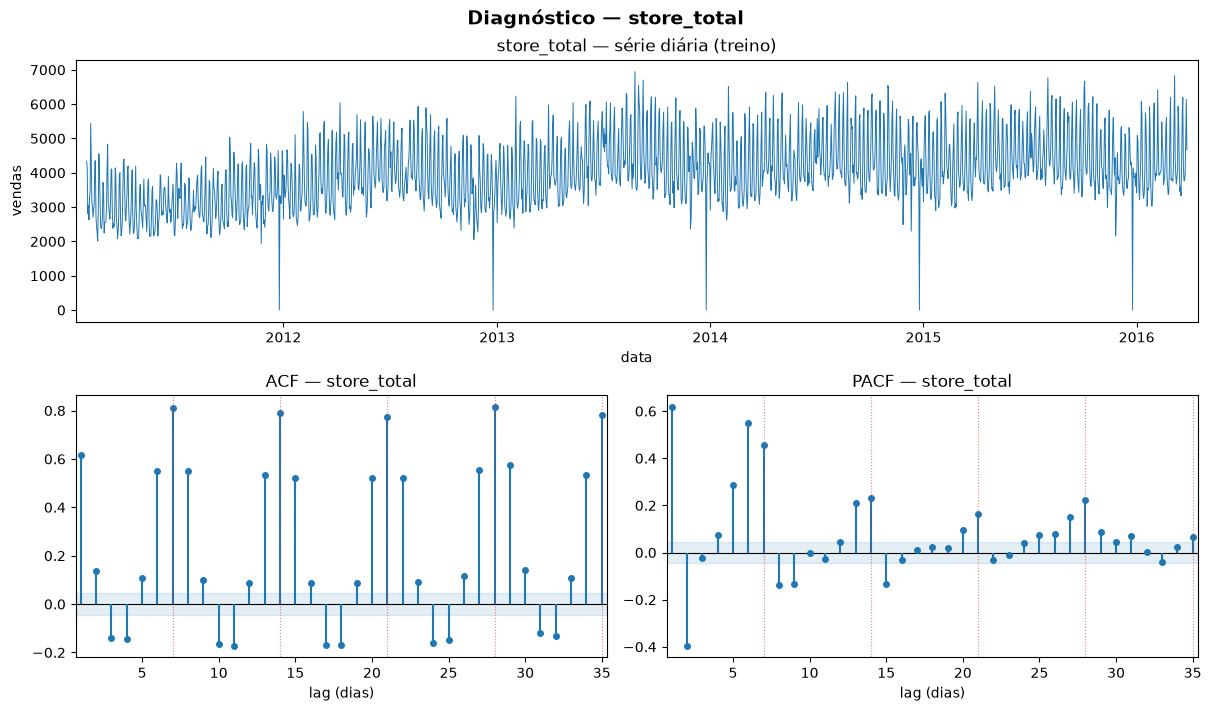

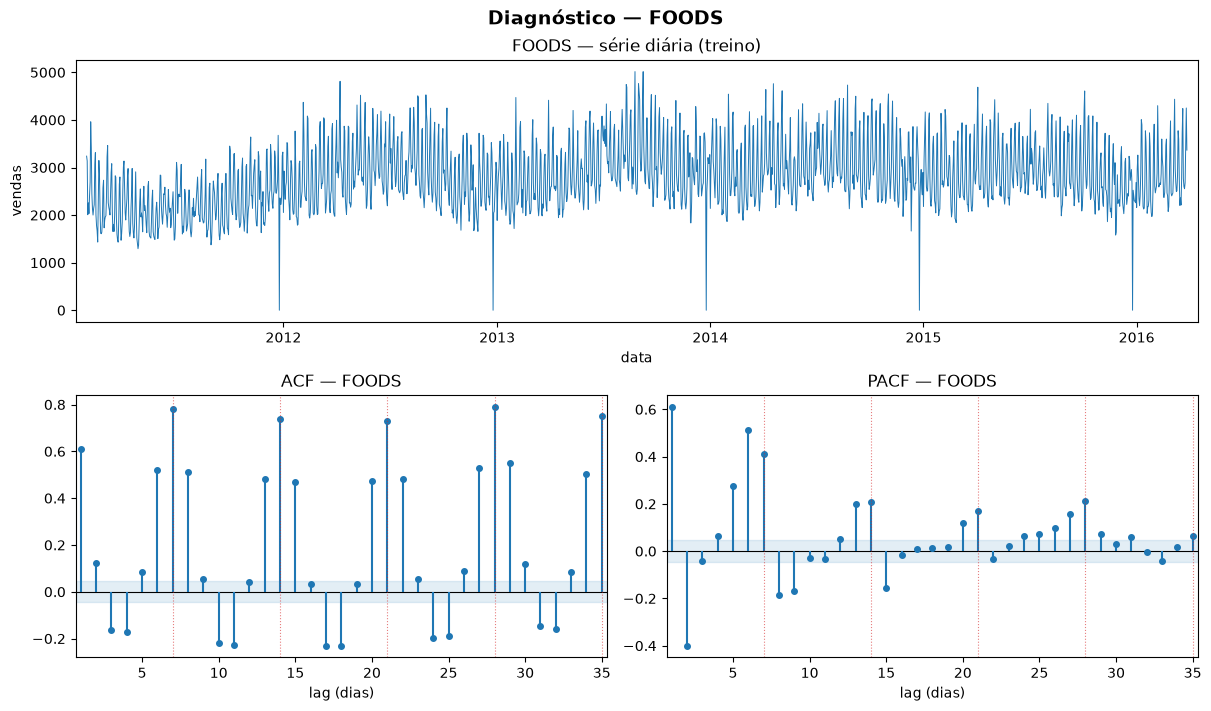

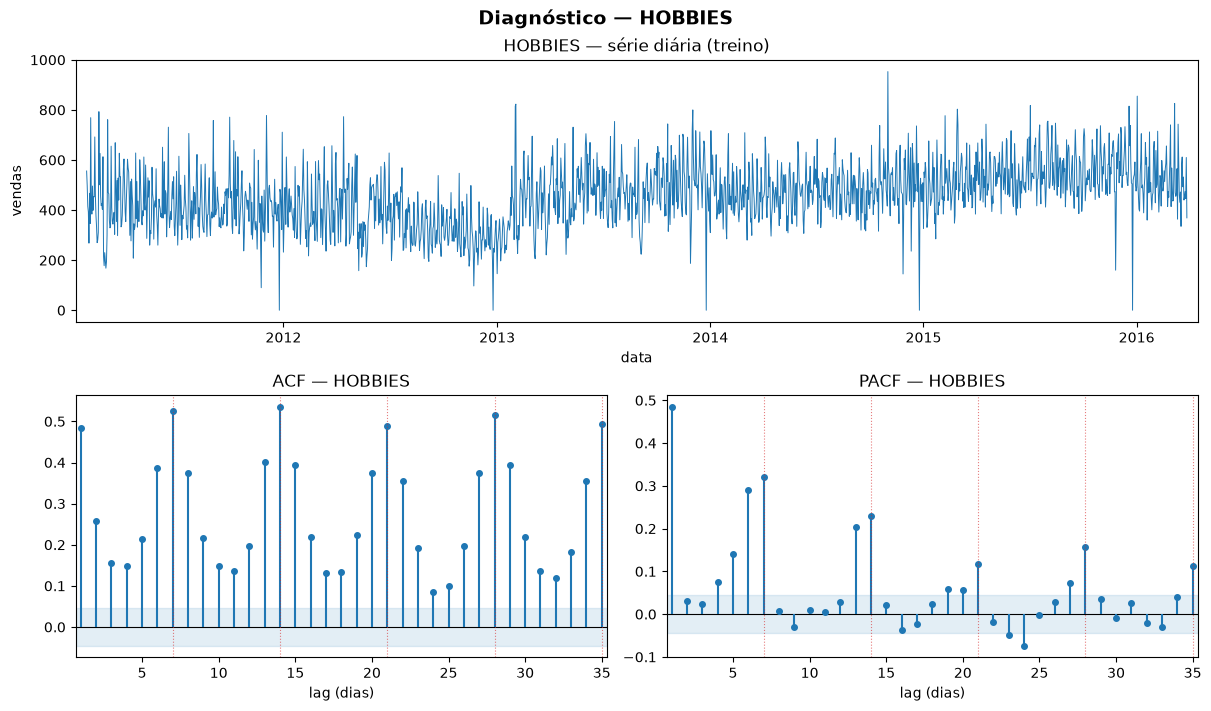

In [3]:
for s in SERIES:
    fig = figura_diagnostico(treino[s], s, salvar=f'figuras/diagnostico_{s}.png')
    display(fig)
    plt.close(fig)

Para cada série temos a série diária no tempo (em cima) e os correlogramas ACF e PACF (embaixo). Onde a faixa azul clara é a banda de ruído branco (±1,96/√n) e as linhas vermelhas pontilhadas marcam os múltiplos do período semanal (7, 14, 21, 28, 35).

In [4]:
# Zeros de calendário (loja fechada)
display(resumo_zeros(treino))

,series,date,dia_semana
0,store_total,2011-12-25,Sunday
1,store_total,2012-12-25,Tuesday
2,store_total,2013-12-25,Wednesday
3,store_total,2014-12-25,Thursday
4,store_total,2015-12-25,Friday
5,FOODS,2011-12-25,Sunday
6,FOODS,2012-12-25,Tuesday
7,FOODS,2013-12-25,Wednesday
8,FOODS,2014-12-25,Thursday
9,FOODS,2015-12-25,Friday


## Comentário do diagnóstico

**Tendência.** `store_total` e `FOODS` têm tendência de alta de 2011 até cerca de 2013–2014 (pois a média anual de `store_total` sobe de ~3.1k para ~4.3k) e depois estabilizam num platô. `HOBBIES` não tem tendência monotônica clara: o nível cai até o fim de 2012 e dá um salto no início de 2013 (quebra de nível), ficando mais alto e levemente crescente daí em diante. Em todas as séries a média não é constante no tempo, o que, junto com o decaimento lento da ACF, indica não estacionaridade na média e a necessidade de uma diferença regular (d = 1) antes de modelar.

**Sazonalidade semanal (m = 7).** É um padrão forte das séries. O fim de semana fica ~40% acima do meio da semana, a segunda é elevada e ter–qua–qui formam o vale. Isso aparece nos correlogramas como picos nítidos da ACF nos lags 7, 14, 21, 28 e 35 que decaem devagar, e isto é uma evidência de sazonalidade semanal não estacionária, sugerindo também uma diferença sazonal (D = 1, m = 7). A PACF tem um pico grande no lag 1 e massa relevante até o lag 7, coerente com componente AR de curto prazo somada à sazonal. A sazonalidade é dominante em `store_total` e `FOODS` (ACF no lag 7 ≈ 0,81 e 0,78) e mais fraca/ruidosa em `HOBBIES` (ACF no lag 7 ≈ 0,53), mas ainda presente.

**Outliers / zeros de calendário.** O único zero recorrente é 25/12 de cada ano (2011–2015), então provavelmente a loja fecha no Natal, por isso as três séries zeram nessas 5 datas. Fora esses, a grade diária está completa (o `asfreq('D')` não gerou nenhum `NaN`). Aqui apenas sinalizamos os zeros, sem remover nem imputar, um tratamento explícito (como dummy de feriado) é opcional.

**Implicação para o ARIMA/SARIMA.** O diagnóstico aponta para um modelo **SARIMA com `d = 1` e `D = 1`, `m = 7`**, com as ordens de `p, q` e `P, Q` identificadas pela ACF/PACF da série já diferenciada, na etapa de modelagem.

## Resultados na validação

As métricas vêm de `metricas.csv`: MAE, RMSE e MASE nos 28 dias de validação (2016-03-28 a 2016-04-24), para as três séries e os seis modelos (quatro baselines, SARIMA e, da Task 2, o linear).

MAE e RMSE estão na unidade da série, então o nível de `store_total` não se compara com o de `HOBBIES`. O MASE divide o MAE da validação pelo MAE in-sample do naive sazonal semanal no treino. Abaixo de 1, o modelo erra menos do que esse naive sazonal dentro da amostra.

In [5]:
metricas = carregar_metricas()
display(tabela_metricas(metricas))


,series,modelo,mae,rmse,mase
0,store_total,média,813.9,1109.6,1.871
1,store_total,naive,862.8,966.6,1.983
2,store_total,naive sazonal,459.2,655.5,1.056
3,store_total,drift,863.3,966.8,1.984
4,store_total,SARIMA,314.9,387.9,0.724
5,store_total,linear,191.8,252.4,0.441
6,FOODS,média,526.9,671.8,1.540
7,FOODS,naive,664.6,722.9,1.943
8,FOODS,naive sazonal,343.9,420.1,1.005
9,FOODS,drift,665.0,723.3,1.944


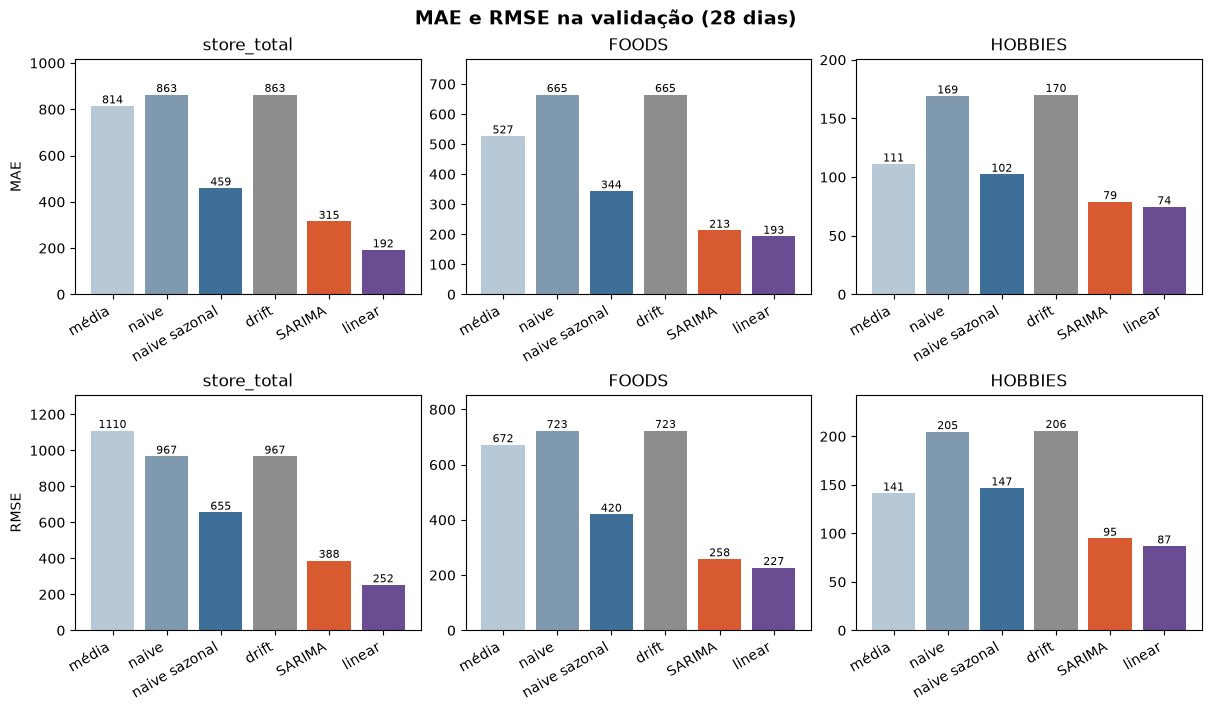

In [6]:
fig = figura_mae_rmse(metricas)
display(fig)
plt.close(fig)


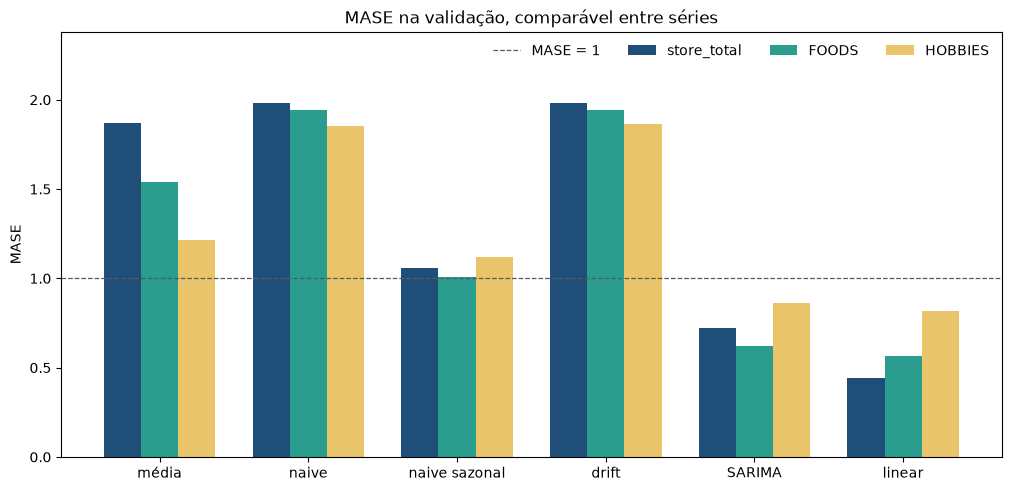

In [7]:
fig = figura_mase(metricas)
display(fig)
plt.close(fig)


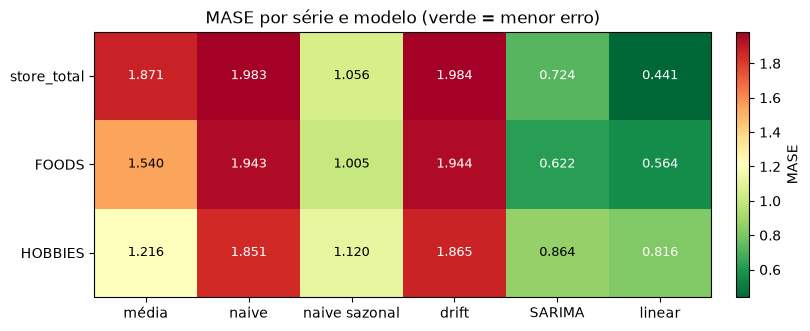

In [8]:
fig = figura_heatmap_mase(metricas)
display(fig)
plt.close(fig)


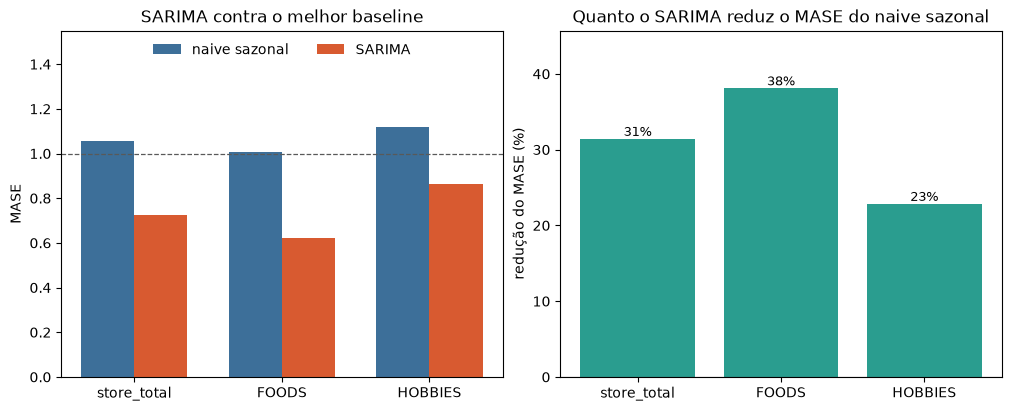

Melhor baseline e SARIMA, por série (MASE):
  store_total: naive sazonal 1.056  →  SARIMA 0.724  (31% menor que o naive sazonal)
  FOODS: naive sazonal 1.005  →  SARIMA 0.622  (38% menor que o naive sazonal)
  HOBBIES: naive sazonal 1.120  →  SARIMA 0.864  (23% menor que o naive sazonal)


In [9]:
fig = figura_sarima_vs_naive(metricas)
display(fig)
plt.close(fig)
print(texto_comparacao(metricas))


## Leitura das métricas

Nas três séries o naive sazonal é o melhor dos quatro baselines, e o SARIMA fica abaixo dele em MAE, RMSE e MASE. Média, naive e drift ficam perto de MASE 2 em `store_total` e `FOODS`: sem a semana, o erro na validação é cerca do dobro do naive sazonal in-sample.

O ganho do SARIMA é maior em `FOODS` e `store_total`, onde a sazonalidade semanal é mais forte, e menor em `HOBBIES`, a série mais ruidosa no diagnóstico. Em nenhuma série o SARIMA perde para a média nem para o naive sazonal.

## Task 2 — Modelo linear

**Especificação.** Regressão linear por mínimos quadrados (`src/linear.py`), com **um ajuste por série**: `store_total`, `FOODS` e `HOBBIES` não dividem a mesma tabela nem os coeficientes. A estratégia é **direta**: para cada dia do horizonte as colunas usam só o calendário do dia previsto e o que já se conhece na origem (2016-03-27). Nenhum lag de y entra, então nenhuma previsão volta como coluna e o y da validação nunca entra.

Colunas:
- **calendário do dia previsto:** dummies de dia da semana (domingo como referência), Natal e véspera de Natal, e 3 pares seno/cosseno da sazonalidade anual (Fourier, período 365,25);
- **de `covariaveis.csv`:** `snap_CA`, um indicador de evento (`event_type_1` ou `event_type_2` preenchido) e o preço semanal da própria série (`preco_store_total`, `preco_FOODS` ou `preco_HOBBIES`), padronizado com média e desvio calculados **só na janela de treino**.

**Hiperparâmetros fixados fora da validação.** Janela de ajuste (treino inteiro, 730 ou 365 dias), tendência linear (sim/não) e número de pares de Fourier (0 ou 3) foram escolhidos por `selecionar()`: MASE médio em 28 dias a partir de quatro origens que terminam dentro do treino (2015-12-06, 2016-01-03, 2016-01-31, 2016-02-28). Venceu **janela de 365 dias, K = 3, sem tendência**. Os 28 dias de validação não entraram nessa escolha.

**HOBBIES vs FOODS.** A especificação é a mesma nas três séries, mas `HOBBIES` não herda o ajuste de `FOODS`: tem seus próprios coeficientes e usa o próprio preço (`preco_HOBBIES`). A seleção também foi feita olhando cada série, e em `HOBBIES` a configuração vencedora praticamente empata com a sem Fourier (MASE 0,754 vs 0,756), sinal de que a sazonalidade anual pesa pouco nessa série.

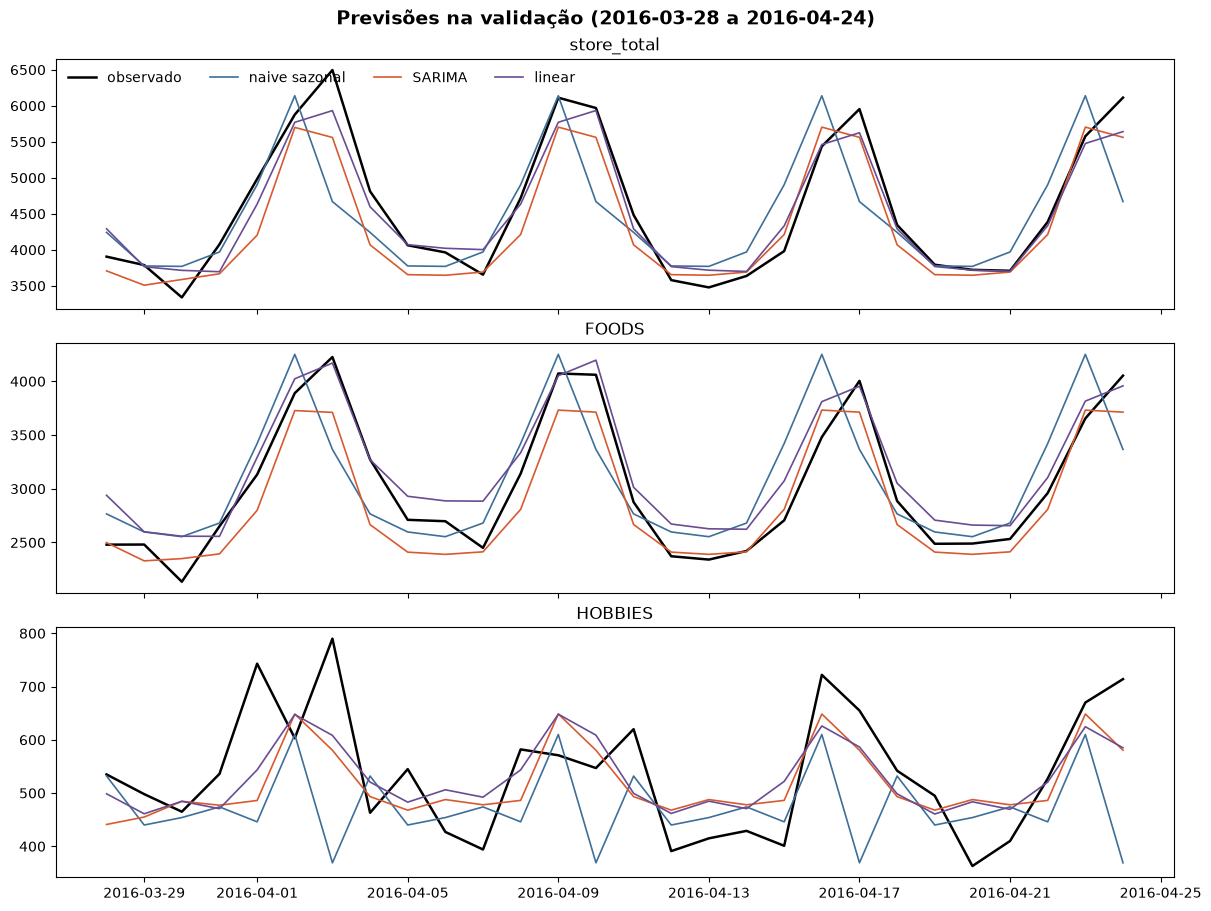

linear contra naive sazonal e SARIMA (- = erra menos, + = erra mais):
  store_total: vs naive sazonal: MAE -58%, RMSE -61%, MASE -58% | vs SARIMA: MAE -39%, RMSE -35%, MASE -39%
  FOODS: vs naive sazonal: MAE -44%, RMSE -46%, MASE -44% | vs SARIMA: MAE -9%, RMSE -12%, MASE -9%
  HOBBIES: vs naive sazonal: MAE -27%, RMSE -41%, MASE -27% | vs SARIMA: MAE -6%, RMSE -8%, MASE -6%


In [10]:
fig = figura_previsoes(val)
display(fig)
plt.close(fig)
print(texto_classe(metricas, 'linear'))

### Leitura dos gráficos e conclusões do linear

**O linear não perde para o naive sazonal em nenhuma série nem em nenhuma métrica.** O MAE cai 58% em `store_total`, 44% em `FOODS` e 27% em `HOBBIES`; o RMSE cai entre 41% e 61%.

**Contra o SARIMA, o linear também erra menos nas três séries e nas três métricas**, com folga em `store_total` (MASE 0,441 vs 0,724, −39%) e por margem menor em `FOODS` (−9% no MAE, −12% no RMSE) e `HOBBIES` (−6% no MAE, −8% no RMSE). Ele é o melhor modelo da tabela até aqui nas três séries.

**Por que o naive sazonal vai mal: a Páscoa.** O último dia do treino, 2016-03-27, é domingo de Páscoa, e as vendas caíram (`store_total` 4.669, contra 6.197 no domingo anterior; `HOBBIES` 369). O naive sazonal repete essa semana quatro vezes, então prevê um domingo baixo em todas as semanas da validação, enquanto o observado é pico de fim de semana. É o vale azul de todo domingo no gráfico, e é o que mais pesa no RMSE dele.

**Por que o SARIMA fica abaixo do linear: nível.** O SARIMA acerta o formato da semana, mas, ancorado na última semana pela diferença sazonal, prevê sistematicamente abaixo do observado: o viés médio é −229 em `store_total` e −159 em `FOODS`, visível nos picos de sábado/domingo achatados em `FOODS` (~3.700 contra ~4.100–4.200 observados). O linear não depende da última semana: o nível vem da média da janela de 365 dias, e a semana vem das dummies. Por isso acompanha bem os picos de fim de semana.

**Onde o linear erra.** Em `FOODS` ele superestima os dias de semana (viés médio +170), por exemplo ~2.650 previsto contra ~2.400 observado entre 12 e 14/04. É o oposto do SARIMA, que fica abaixo. A superestimação aparece tanto nos dias de SNAP (01 a 10/04) quanto depois deles, então não é efeito do SNAP: é o nível médio da janela de 365 dias, que fica acima do nível atual dos dias úteis de `FOODS`. Em `HOBBIES` os três modelos produzem curvas suaves e nenhum capta os picos isolados (01/04, 03/04, 16/04, de 720 a 790 unidades). Linear e SARIMA ficam quase sobrepostos, o que explica a vantagem pequena (MASE 0,816 vs 0,864). A série é a mais ruidosa (ACF no lag 7 ≈ 0,53 no diagnóstico), e boa parte da variação diária não é explicada nem pelo calendário nem pelas covariáveis.

**Resumo.** O ganho do linear vem de duas coisas que o SARIMA não tem: o nível estimado numa janela longa, em vez de copiado da última semana (que aqui era atípica por causa da Páscoa), e as covariáveis conhecidas na origem (SNAP, evento e preço). A ordem de dificuldade das séries se mantém: `HOBBIES` continua com o maior MASE em todos os modelos.